# LÀM SẠCH VĂN BẢN, BAG-OF-WORDS VÀ TF-IDF

**Đề tài:** Phân loại cảm xúc từ phản hồi của sinh viên  
**Dữ liệu:** `student_feedback_dataset.csv`  
**Văn bản đầu vào:** `feedback_text` | **Nhãn mục tiêu:** `sentiment_label`

## Mục tiêu
1. Kiểm tra chất lượng trường văn bản và nhãn liên quan.
2. Làm sạch văn bản có giải thích, tránh xóa thông tin cảm xúc máy móc.
3. Thử nghiệm Bag-of-Words (CountVectorizer) và TF-IDF.
4. So sánh unigram/bigram và lưu dữ liệu cho thành viên huấn luyện mô hình.

**Chống data leakage:** Chia train/test trước; chỉ `fit` vectorizer trên `X_train`, sau đó `transform` `X_test`. Không đưa cột định danh/ngữ cảnh vào vectorizer.

**Thiết lập chia dữ liệu:** 80% train, 20% test, `random_state=42`, `stratify=y`. Phải thống nhất thiết lập này với notebook huấn luyện mô hình.

## 1. Import thư viện và đọc dữ liệu

In [1]:
import json
import sys
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy.sparse import save_npz
import joblib
import re

RANDOM_STATE = 42
TEST_SIZE = 0.20
TEXT_COL, TARGET_COL = "feedback_text", "sentiment_label"
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd,*cwd.parents] if (p/'data'/'student_feedback_dataset.csv').is_file()),None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/student_feedback_dataset.csv trong dự án")
sys.path.insert(0,str(PROJECT_ROOT))
from src.text_utils import clean_text

DATA_PATH = PROJECT_ROOT / 'data' / 'student_feedback_dataset.csv'
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'member2_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)
if any(c not in df.columns for c in (TEXT_COL,TARGET_COL)):
    raise ValueError(f"Dataset cần hai cột: {TEXT_COL}, {TARGET_COL}")
print("Nguồn dữ liệu:", DATA_PATH)
print("Kích thước:", df.shape)
display(df[[TEXT_COL,TARGET_COL]].head())

Nguồn dữ liệu: D:\Nam3\MachineLearning\Nhom-7_Phan_loai_cam_xuc_tu_phan_hoi_cua_sinh_vien-main\data\student_feedback_dataset.csv
Kích thước: (1223, 11)


,feedback_text,sentiment_label
0,Attack medical dog technology top several insi...,negative
1,Wait worry speak program child past beautiful ...,positive
2,Bank those report box your treatment accept in...,neutral
3,Can character million listen right amount ask ...,positive
4,Good cost political street dream finish figure.,negative


## 2. Kiểm tra chất lượng dữ liệu

Kiểm tra giá trị thiếu, văn bản rỗng, dòng trùng lặp, phân bố nhãn và độ dài phản hồi. Dù EDA đã có bước tương tự, kiểm tra lại giúp notebook này chạy độc lập.

In [2]:
quality = pd.DataFrame({
    "Số lượng thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": (df.isna().mean() * 100).round(2)
})
display(quality.loc[[TEXT_COL, TARGET_COL]])

empty_count = df[TEXT_COL].fillna("").astype(str).str.strip().eq("").sum()
print("Văn bản rỗng:", int(empty_count))
print("Dòng trùng lặp hoàn toàn:", int(df.duplicated().sum()))

label_summary = pd.DataFrame({
    "Số lượng": df[TARGET_COL].value_counts(),
    "Tỷ lệ (%)": (df[TARGET_COL].value_counts(normalize=True) * 100).round(2)
})
display(label_summary)

raw_words = df[TEXT_COL].fillna("").astype(str).str.split().str.len()
raw_chars = df[TEXT_COL].fillna("").astype(str).str.len()
print("Thống kê số từ:")
display(raw_words.describe().to_frame("Số từ"))
print("Thống kê số ký tự:")
display(raw_chars.describe().to_frame("Số ký tự"))

,Số lượng thiếu,Tỷ lệ thiếu (%)
feedback_text,0,0.0
sentiment_label,0,0.0


Văn bản rỗng: 0
Dòng trùng lặp hoàn toàn: 0


,Số lượng,Tỷ lệ (%)
sentiment_label,,
positive,489,39.98
neutral,368,30.09
negative,366,29.93


Thống kê số từ:


,Số từ
count,1223.000000
mean,11.453802
std,3.910113
min,4.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,22.000000


Thống kê số ký tự:


,Số ký tự
count,1223.000000
mean,75.157809
std,26.242676
min,22.000000
25%,55.000000
50%,72.000000
75%,93.000000
max,160.000000


### 2.1. Trực quan hóa phân bố nhãn và độ dài văn bản

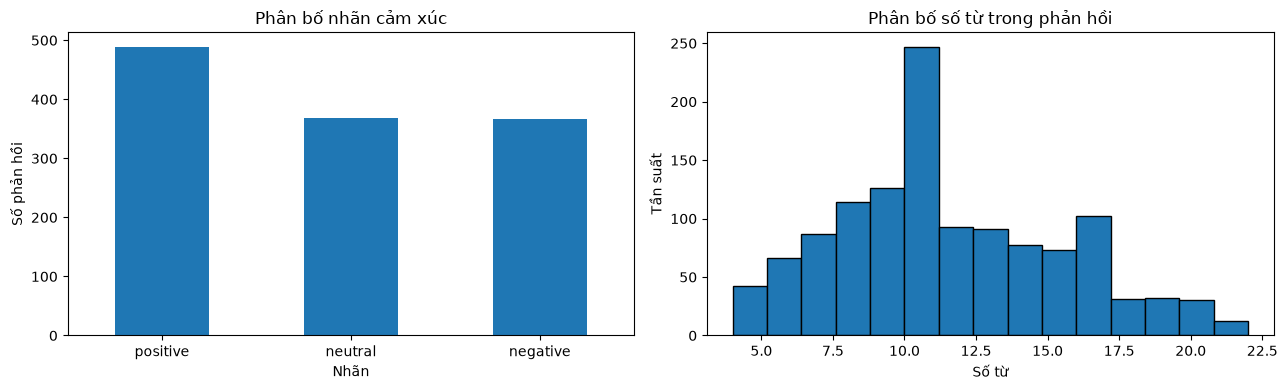

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
label_summary["Số lượng"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Phân bố nhãn cảm xúc")
axes[0].set_xlabel("Nhãn")
axes[0].set_ylabel("Số phản hồi")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(raw_words, bins=15, edgecolor="black")
axes[1].set_title("Phân bố số từ trong phản hồi")
axes[1].set_xlabel("Số từ")
axes[1].set_ylabel("Tần suất")
plt.tight_layout()
plt.show()

### 2.2. Kiểm tra các trường có sẵn

Dataset có thể có `preprocessed_text`, `emotion_tag` và các cột ngữ cảnh. Ta so sánh văn bản làm sạch với cột có sẵn; bảng chéo nhãn chỉ để rà soát, không tự động kết luận nhãn sai. Chỉ dùng `feedback_text` làm đầu vào và `sentiment_label` làm nhãn; không đưa ID/ngữ cảnh/nhãn phụ vào vectorizer.

In [4]:
raw_text = df[TEXT_COL].fillna("").astype(str)
special_summary = pd.Series({
    "Số văn bản có URL": raw_text.str.contains(r"https?://|www\.", case=False, regex=True).sum(),
    "Số văn bản có chữ số": raw_text.str.contains(r"\d", regex=True).sum(),
    "Số văn bản có dấu câu/ký tự đặc biệt": raw_text.str.contains(r"[^a-zA-Z0-9\s]", regex=True).sum()
}, name="Số văn bản")
display(special_summary.to_frame())

if "emotion_tag" in df.columns:
    print("Bảng chéo sentiment_label và emotion_tag (chỉ rà soát dữ liệu):")
    display(pd.crosstab(df[TARGET_COL], df["emotion_tag"], margins=True))

,Số văn bản
Số văn bản có URL,0
Số văn bản có chữ số,0
Số văn bản có dấu câu/ký tự đặc biệt,1223


Bảng chéo sentiment_label và emotion_tag (chỉ rà soát dữ liệu):


emotion_tag,anger,fear,joy,neutral,sadness,surprise,All
sentiment_label,,,,,,,
negative,61,57,64,62,57,65,366
neutral,63,66,55,61,59,64,368
positive,70,82,86,85,93,73,489
All,194,205,205,208,209,202,1223


## 3. Làm sạch văn bản theo quy tắc dùng chung
Nhóm chuẩn hóa chữ thường, bỏ URL, dấu câu không cần thiết và khoảng trắng thừa; giữ số, chữ Unicode, dấu nháy và từ phủ định.
Không xóa stopword một cách máy móc. Quy tắc nằm ở src/text_utils.py để tái sử dụng khi demo.
Việc xóa/mã hóa dữ liệu sẽ được thực hiện trước khi chia train/test và được thống kê rõ ràng.

In [5]:
df['clean_text'] = df[TEXT_COL].apply(clean_text)
print("Văn bản rỗng sau làm sạch:", int(df['clean_text'].eq('').sum()))
display(df[[TEXT_COL,'clean_text',TARGET_COL]].head(12))

Văn bản rỗng sau làm sạch: 0


,feedback_text,clean_text,sentiment_label
0,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative
1,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive
2,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral
3,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive
4,Good cost political street dream finish figure.,good cost political street dream finish figure,negative
5,Month leave doctor single vote say reach be sk...,month leave doctor single vote say reach be sk...,negative
6,Measure challenge series material I history le...,measure challenge series material i history le...,neutral
7,Small message what executive certain evidence ...,small message what executive certain evidence ...,positive
8,Civil eat memory become beyond interview fall ...,civil eat memory become beyond interview fall ...,negative
9,Machine tend simply beat which when remain why...,machine tend simply beat which when remain why...,negative


### 3.1. Đối chiếu với `preprocessed_text` có sẵn

In [6]:
if "preprocessed_text" in df.columns:
    preprocessed = df["preprocessed_text"].fillna("").astype(str)
    same = df["clean_text"].eq(preprocessed)
    print(f"Tỷ lệ khớp với preprocessed_text: {same.mean()*100:.2f}%")
    print("Số dòng không khớp:", int((~same).sum()))
    if (~same).any():
        display(df.loc[~same, [TEXT_COL, "clean_text", "preprocessed_text"]].head(10))
else:
    print("Dataset không có cột preprocessed_text.")

Tỷ lệ khớp với preprocessed_text: 100.00%
Số dòng không khớp: 0


### 3.2. So sánh độ dài trước và sau làm sạch

In [7]:
length_check = pd.DataFrame({
    "Ký tự trước": df[TEXT_COL].fillna("").astype(str).str.len(),
    "Ký tự sau": df["clean_text"].str.len(),
    "Số từ trước": df[TEXT_COL].fillna("").astype(str).str.split().str.len(),
    "Số từ sau": df["clean_text"].str.split().str.len()
})
display(length_check.describe().round(2))

,Ký tự trước,Ký tự sau,Số từ trước,Số từ sau
count,1223.00,1223.00,1223.00,1223.00
mean,75.16,74.16,11.45,11.45
std,26.24,26.24,3.91,3.91
min,22.00,21.00,4.00,4.00
25%,55.00,54.00,8.00,8.00
50%,72.00,71.00,11.00,11.00
75%,93.00,92.00,14.00,14.00
max,160.00,159.00,22.00,22.00


## 4. Làm sạch dữ liệu theo hàng và chia train/test
Bỏ mẫu rỗng/thiếu nhãn và kiểm tra trùng nội dung trước khi chia để giảm nguy cơ dữ liệu trùng ở cả train và test.
Nếu một nội dung có nhiều nhãn, nhóm loại nhóm mâu thuẫn và ghi lại số lượng (quy tắc lựa chọn của nhóm, cần giải thích trong báo cáo).
Chia 80/20, random_state=42, stratify=y (nếu số mẫu mỗi lớp đủ điều kiện).

In [8]:
df = df.reset_index().rename(columns={'index':'source_index'})
valid_mask = df['clean_text'].ne('') & df[TARGET_COL].notna() & df[TARGET_COL].astype(str).str.strip().ne('')
removed_invalid = int((~valid_mask).sum())
model_df = df.loc[valid_mask,["source_index",TEXT_COL,"clean_text",TARGET_COL]].copy()
conflict_counts = model_df.groupby('clean_text')[TARGET_COL].nunique()
conflicting_texts = set(conflict_counts[conflict_counts > 1].index)
conflicting_records = model_df.loc[model_df['clean_text'].isin(conflicting_texts)].copy()
conflicting_records.to_csv(OUTPUT_DIR/'conflicting_labels.csv',index=False,encoding='utf-8-sig')
model_df = model_df.loc[~model_df['clean_text'].isin(conflicting_texts)].copy()
removed_duplicates = int(model_df.duplicated('clean_text').sum())
model_df = model_df.drop_duplicates('clean_text',keep='first').reset_index(drop=True)
if model_df[TARGET_COL].nunique() < 2:
    raise ValueError('Cần ít nhất 2 nhãn mục tiêu để phân loại')
if model_df[TARGET_COL].value_counts().min() < 2:
    raise ValueError('Mỗi lớp cần >= 2 mẫu để chia train/test phân tầng.')
if int(np.ceil(TEST_SIZE*len(model_df))) < model_df[TARGET_COL].nunique():
    raise ValueError('Số mẫu test quá nhỏ so với số lớp; cần thay đổi tỷ lệ chia.')

train_df, test_df = train_test_split(
    model_df, test_size=TEST_SIZE, random_state=RANDOM_STATE,
    stratify=model_df[TARGET_COL]
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
X_train, X_test = train_df['clean_text'], test_df['clean_text']
y_train, y_test = train_df[TARGET_COL], test_df[TARGET_COL]
print('Bỏ mẫu thiếu/rỗng:',removed_invalid)
print('Bỏ mẫu nhãn mâu thuẫn:',len(conflicting_records))
print('Bỏ bản ghi lặp nội dung:',removed_duplicates)
print('Train:',len(train_df),'| Test:',len(test_df))
print('Trùng nội dung giữa train/test:',len(set(X_train)&set(X_test)))
display(pd.concat({"train":y_train.value_counts(normalize=True),"test":y_test.value_counts(normalize=True)},axis=1).fillna(0).round(3))

Bỏ mẫu thiếu/rỗng: 0
Bỏ mẫu nhãn mâu thuẫn: 0
Bỏ bản ghi lặp nội dung: 0
Train: 978 | Test: 245
Trùng nội dung giữa train/test: 0


,train,test
sentiment_label,,
positive,0.400,0.400
neutral,0.301,0.302
negative,0.300,0.298


## 5. Bag-of-Words (BoW) – CountVectorizer

BoW tạo ma trận đếm số lần xuất hiện của từ/cụm từ. Thử nghiệm Unigram `(1,1)` và Unigram + Bigram `(1,2)`. Cùng dùng `min_df=1`, `max_df=1.0`, `max_features=5000` để so sánh có kiểm soát.

In [9]:
bow_configs = {
    "BoW_Unigram": CountVectorizer(ngram_range=(1, 1), min_df=1, max_df=1.0, max_features=5000),
    "BoW_Unigram_Bigram": CountVectorizer(ngram_range=(1, 2), min_df=1, max_df=1.0, max_features=5000)
}
bow_results = {}
for name, vectorizer in bow_configs.items():
    Xtr = vectorizer.fit_transform(X_train)
    Xte = vectorizer.transform(X_test)
    bow_results[name] = {"vectorizer": vectorizer, "X_train": Xtr, "X_test": Xte}
    print(f"--- {name} ---")
    print("Train:", Xtr.shape, "| Test:", Xte.shape)
    print("Số đặc trưng:", len(vectorizer.get_feature_names_out()))
    print("20 đặc trưng đầu:", vectorizer.get_feature_names_out()[:20].tolist())

--- BoW_Unigram ---
Train: (978, 969) | Test: (245, 969)
Số đặc trưng: 969
20 đặc trưng đầu: ['ability', 'able', 'about', 'above', 'accept', 'according', 'account', 'across', 'act', 'action', 'activity', 'actually', 'add', 'address', 'administration', 'admit', 'adult', 'affect', 'after', 'again']
--- BoW_Unigram_Bigram ---
Train: (978, 5000) | Test: (245, 5000)
Số đặc trưng: 5000
20 đặc trưng đầu: ['ability', 'ability either', 'ability example', 'ability history', 'ability in', 'ability leader', 'ability leg', 'ability military', 'ability partner', 'ability push', 'ability service', 'ability set', 'ability side', 'ability speak', 'able', 'able above', 'about', 'above', 'accept', 'according']


### 5.1. Các từ có tần suất cao trong BoW Unigram

,Từ,Tần suất trong train
0,history,25
1,hour,24
2,only,23
3,decision,23
4,win,23
5,push,22
6,perform,22
7,medical,21
8,someone,21
9,artist,21


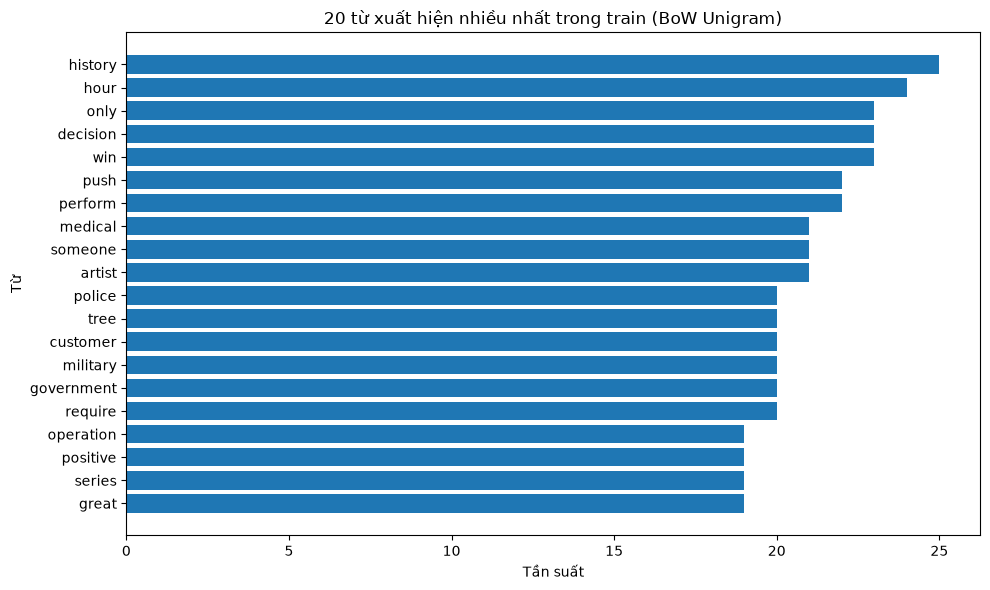

In [10]:
bow_vectorizer = bow_results["BoW_Unigram"]["vectorizer"]
bow_counts = np.asarray(bow_results["BoW_Unigram"]["X_train"].sum(axis=0)).ravel()
bow_terms = bow_vectorizer.get_feature_names_out()
top_idx = np.argsort(bow_counts)[::-1][:20]
top_bow = pd.DataFrame({
    "Từ": bow_terms[top_idx],
    "Tần suất trong train": bow_counts[top_idx].astype(int)
})
display(top_bow)

plt.figure(figsize=(10, 6))
plt.barh(top_bow["Từ"][::-1], top_bow["Tần suất trong train"][::-1])
plt.title("20 từ xuất hiện nhiều nhất trong train (BoW Unigram)")
plt.xlabel("Tần suất")
plt.ylabel("Từ")
plt.tight_layout()
plt.show()

## 6. TF-IDF – TfidfVectorizer

TF-IDF gán trọng số dựa trên tần suất từ trong văn bản và mức độ phổ biến của từ trong tập train. Dùng cùng cấu hình unigram/bigram để so sánh với BoW. Mặc định chuẩn hóa L2, sử dụng IDF và làm trơn IDF.

In [11]:
tfidf_configs = {
    "TFIDF_Unigram": TfidfVectorizer(
        ngram_range=(1, 1), min_df=1, max_df=1.0, max_features=5000,
        use_idf=True, smooth_idf=True, sublinear_tf=False
    ),
    "TFIDF_Unigram_Bigram": TfidfVectorizer(
        ngram_range=(1, 2), min_df=1, max_df=1.0, max_features=5000,
        use_idf=True, smooth_idf=True, sublinear_tf=False
    )
}
tfidf_results = {}
for name, vectorizer in tfidf_configs.items():
    Xtr = vectorizer.fit_transform(X_train)
    Xte = vectorizer.transform(X_test)
    tfidf_results[name] = {"vectorizer": vectorizer, "X_train": Xtr, "X_test": Xte}
    print(f"--- {name} ---")
    print("Train:", Xtr.shape, "| Test:", Xte.shape)
    print("Số đặc trưng:", len(vectorizer.get_feature_names_out()))
    print("20 đặc trưng đầu:", vectorizer.get_feature_names_out()[:20].tolist())

--- TFIDF_Unigram ---
Train: (978, 969) | Test: (245, 969)
Số đặc trưng: 969
20 đặc trưng đầu: ['ability', 'able', 'about', 'above', 'accept', 'according', 'account', 'across', 'act', 'action', 'activity', 'actually', 'add', 'address', 'administration', 'admit', 'adult', 'affect', 'after', 'again']
--- TFIDF_Unigram_Bigram ---
Train: (978, 5000) | Test: (245, 5000)
Số đặc trưng: 5000
20 đặc trưng đầu: ['ability', 'ability either', 'ability example', 'ability history', 'ability in', 'ability leader', 'ability leg', 'ability military', 'ability partner', 'ability push', 'ability service', 'ability set', 'ability side', 'ability speak', 'able', 'able above', 'about', 'above', 'accept', 'according']


### 6.1. Quan sát IDF của các từ

In [12]:
tfidf_vectorizer = tfidf_results["TFIDF_Unigram"]["vectorizer"]
idf_table = pd.DataFrame({
    "Từ": tfidf_vectorizer.get_feature_names_out(),
    "IDF": tfidf_vectorizer.idf_
})
print("10 từ có IDF thấp nhất:")
display(idf_table.nsmallest(10, "IDF").reset_index(drop=True))
print("10 từ có IDF cao nhất:")
display(idf_table.nlargest(10, "IDF").reset_index(drop=True))

10 từ có IDF thấp nhất:


,Từ,IDF
0,history,4.628435
1,hour,4.667656
2,decision,4.708478
3,only,4.708478
4,win,4.708478
5,perform,4.751037
6,push,4.751037
7,artist,4.795489
8,someone,4.795489
9,customer,4.842009


10 từ có IDF cao nhất:


,Từ,IDF
0,assume,6.500237
1,remember,6.500237
2,take,6.500237
3,adult,6.277094
4,article,6.277094
5,contain,6.277094
6,free,6.277094
7,heart,6.277094
8,man,6.277094
9,policy,6.277094


## 7. So sánh các cấu hình BoW và TF-IDF

Bảng dưới đây mô tả kích thước biểu diễn và độ thưa của ma trận, **không phải chất lượng phân loại**. Muốn kết luận cấu hình nào dự đoán tốt hơn, cần huấn luyện cùng mô hình và so sánh F1-score, Precision, Recall, Accuracy, Confusion Matrix.

In [13]:
all_results = {**bow_results, **tfidf_results}
comparison_rows = []
for name, result in all_results.items():
    Xtr, Xte = result["X_train"], result["X_test"]
    total = Xtr.shape[0] * Xtr.shape[1]
    density = Xtr.nnz / total if total else 0
    comparison_rows.append({
        "Cấu hình": name,
        "Số mẫu train": Xtr.shape[0],
        "Số đặc trưng": Xtr.shape[1],
        "Kích thước test": str(Xte.shape),
        "Phần tử khác 0 (train)": int(Xtr.nnz),
        "Mật độ train (%)": round(density*100, 3),
        "Độ thưa train (%)": round((1-density)*100, 3)
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Cấu hình,Số mẫu train,Số đặc trưng,Kích thước test,Phần tử khác 0 (train),Mật độ train (%),Độ thưa train (%)
0,BoW_Unigram,978,969,"(245, 969)",11109,1.172,98.828
1,BoW_Unigram_Bigram,978,5000,"(245, 5000)",15184,0.311,99.689
2,TFIDF_Unigram,978,969,"(245, 969)",11109,1.172,98.828
3,TFIDF_Unigram_Bigram,978,5000,"(245, 5000)",15184,0.311,99.689


### 7.1. Hướng diễn giải
- Bigram thêm thông tin về cặp từ liên tiếp, có thể nhận diện một số cụm từ; đổi lại số đặc trưng và độ thưa thường tăng.
- BoW giữ số lần xuất hiện; TF-IDF điều chỉnh trọng số theo mức độ phổ biến của từ trong tập train.
- Không thể chọn phương pháp tốt nhất chỉ dựa vào số chiều hoặc độ thưa.
- Nếu số chiều quá lớn, có thể thử `min_df=2` hoặc giảm `max_features` ở thí nghiệm bổ sung; cần báo cáo rõ cấu hình.

## 8. Kiểm tra nhất quán train/test và chống data leakage

In [14]:
for name, result in all_results.items():
    assert result["X_train"].shape[1] == result["X_test"].shape[1]
    print(f"{name}: train={result['X_train'].shape}, test={result['X_test'].shape}; fit chỉ trên train.")
print("Đã kiểm tra: số chiều train/test khớp ở tất cả cấu hình.")

BoW_Unigram: train=(978, 969), test=(245, 969); fit chỉ trên train.
BoW_Unigram_Bigram: train=(978, 5000), test=(245, 5000); fit chỉ trên train.
TFIDF_Unigram: train=(978, 969), test=(245, 969); fit chỉ trên train.
TFIDF_Unigram_Bigram: train=(978, 5000), test=(245, 5000); fit chỉ trên train.
Đã kiểm tra: số chiều train/test khớp ở tất cả cấu hình.


## 9. Lưu đầu ra và bàn giao cho Thành viên 3
Tất cả đường dẫn lưu theo thư mục gốc dự án: results/member2_outputs/.
Lưu train.csv, test.csv (có văn bản trước/sau tiền xử lý, nhãn, chỉ số gốc), ma trận .npz, vectorizer .joblib, nhãn và experiment_config.json.
Thành viên 3 sẽ đọc chính những file này, không chia dữ liệu lại hay fit vectorizer trên test.

In [15]:
# Xuất split nhất quán, đủ thông tin để huấn luyện và phân tích lỗi.
train_df.to_csv(OUTPUT_DIR/'train.csv',index=False,encoding='utf-8-sig')
test_df.to_csv(OUTPUT_DIR/'test.csv',index=False,encoding='utf-8-sig')
model_df.to_csv(OUTPUT_DIR/'cleaned_feedback.csv',index=False,encoding='utf-8-sig')
y_train.rename(TARGET_COL).to_csv(OUTPUT_DIR/'y_train.csv',index=False,encoding='utf-8-sig')
y_test.rename(TARGET_COL).to_csv(OUTPUT_DIR/'y_test.csv',index=False,encoding='utf-8-sig')
pd.concat([
    train_df[['source_index']].assign(split='train'),
    test_df[['source_index']].assign(split='test')
],ignore_index=True).to_csv(OUTPUT_DIR/'split_indices.csv',index=False)
for name, result in all_results.items():
    save_npz(OUTPUT_DIR/f'{name}_train.npz',result['X_train'])
    save_npz(OUTPUT_DIR/f'{name}_test.npz',result['X_test'])
    joblib.dump(result['vectorizer'],OUTPUT_DIR/f'{name}_vectorizer.joblib')
config = {
    'text_column':TEXT_COL, 'target_column':TARGET_COL,
    'test_size':TEST_SIZE, 'random_state':RANDOM_STATE, 'stratify':True,
    'source_dataset_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'removed_invalid_rows':removed_invalid,
    'removed_conflicting_label_rows':int(len(conflicting_records)),
    'removed_duplicate_text_rows':removed_duplicates,
    'cleaning_function':'src.text_utils.clean_text',
    'do_not_use_columns_as_features':['sentiment_label','emotion_tag','preprocessed_text'],
    'vectorizers': {
        name:{'kind':'BoW' if name.startswith('BoW') else 'TFIDF',
              'ngram_range':list(result['vectorizer'].ngram_range),
              'min_df':result['vectorizer'].min_df,
              'max_df':result['vectorizer'].max_df,
              'max_features':result['vectorizer'].max_features}
        for name,result in all_results.items()
    }
}
with (OUTPUT_DIR/'experiment_config.json').open('w',encoding='utf-8') as f:
    json.dump(config,f,ensure_ascii=False,indent=2)
comparison_df.to_csv(OUTPUT_DIR/'vectorization_comparison.csv',index=False,encoding='utf-8-sig')
print('Đã xuất dữ liệu thành công:',OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print('-',p.name)

Đã xuất dữ liệu thành công: D:\Nam3\MachineLearning\Nhom-7_Phan_loai_cam_xuc_tu_phan_hoi_cua_sinh_vien-main\results\member2_outputs
- BoW_Unigram_Bigram_test.npz
- BoW_Unigram_Bigram_train.npz
- BoW_Unigram_Bigram_vectorizer.joblib
- BoW_Unigram_test.npz
- BoW_Unigram_train.npz
- BoW_Unigram_vectorizer.joblib
- cleaned_feedback.csv
- conflicting_labels.csv
- experiment_config.json
- preprocessing_notes.md
- split_indices.csv
- test.csv
- TFIDF_Unigram_Bigram_test.npz
- TFIDF_Unigram_Bigram_train.npz
- TFIDF_Unigram_Bigram_vectorizer.joblib
- TFIDF_Unigram_test.npz
- TFIDF_Unigram_train.npz
- TFIDF_Unigram_vectorizer.joblib
- train.csv
- vectorization_comparison.csv
- y_test.csv
- y_train.csv


## 10.Tổng kết và bàn giao
1. Bước làm sạch chỉ chuẩn hóa chữ thường, URL, ký tự đặc biệt và khoảng trắng; không loại bỏ stopword/chữ số/từ phủ định để tránh xóa tín hiệu cảm xúc một cách cơ học.
2. Chỉ cột feedback_text được dùng làm đầu vào; sentiment_label là nhãn. Không dùng emotion_tag hoặc preprocessed_text như một đặc trưng có thể vô tình tiết lộ thông tin về nhãn.
3. Dữ liệu được loại phản hồi rỗng/thiếu nhãn, loại các nhóm trùng văn bản có nhãn mâu thuẫn, rồi loại văn bản trùng trước khi chia train/test có phân tầng; việc loại bỏ được ghi lại ở experiment_config.json.
4. fit_transform chỉ chạy trên train và transform trên test. Khi CV ở file 03, Pipeline fit vectorizer lại trong từng fold của train, không dùng ma trận fit trên toàn tập train để chấm điểm CV.
5. Bốn cách biểu diễn được so sánh là BoW unigram, BoW uni+bigram, TF-IDF unigram, TF-IDF uni+bigram. Đây là so sánh số chiều/độ thưa; chưa phải so sánh hiệu quả dự đoán.

In [16]:
from IPython.display import Markdown

assert 'all_results' in globals() and len(all_results) == 4, 'Cần chạy lần lượt mục 5, 6, 7 trước khi tổng kết.'
preprocessed_match = None
if 'preprocessed_text' in df.columns:
    preprocessed_match = float(df['clean_text'].eq(df['preprocessed_text'].fillna('').astype(str)).mean())

summary_rows = [
    '# Ghi chú tiền xử lý và vector hóa – Thành viên 2',
    '',
    f'- Số bản ghi ban đầu: **{len(df)}**.',
    f'- Bỏ do văn bản rỗng/thiếu nhãn: **{removed_invalid}**; bỏ vì nhãn mâu thuẫn: **{len(conflicting_records)}**; loại trùng nội dung: **{removed_duplicates}**.',
    f'- Số mẫu train: **{len(train_df)}**; test: **{len(test_df)}**; test_size={TEST_SIZE}, random_state={RANDOM_STATE}, stratify=True.',
    f'- Số nội dung trùng giữa train/test: **{len(set(X_train)&set(X_test))}**.',
    '- Không loại stopword hoặc số; giữ các từ phủ định. Xử lý URL và dấu câu nhằm chuẩn hóa văn bản, có thể làm mất sắc thái hoặc biểu tượng cảm xúc; đây là giới hạn cần thảo luận.',
    '- `preprocessed_text` có sẵn chỉ được dùng để kiểm tra, không dùng làm đặc trưng đầu vào.',
]
if preprocessed_match is not None:
    summary_rows.append(f'- Tỷ lệ trùng hoàn toàn với cột `preprocessed_text` có sẵn: **{preprocessed_match*100:.2f}%** (không đồng nghĩa đã chứng minh cải thiện chất lượng mô hình).')
summary_rows.extend(['', '## Bốn cấu hình đặc trưng','', '| Cấu hình | Số đặc trưng | Độ thưa train (%) |','|---|---:|---:|'])
for row in comparison_rows:
    summary_rows.append(f"| {row['Cấu hình']} | {row['Số đặc trưng']} | {row['Độ thưa train (%)']:.3f} |")
summary_rows.extend(['', '## Giải thích lựa chọn', '- `min_df=1`, `max_df=1.0`, `max_features=5000` được giữ cố định để làm rõ tác động của BoW/TF-IDF và unigram/bigram; không dùng tập test để chọn bộ từ vựng.', '- Số chiều cao/độ thưa lớn có thể khiến K-NN khó tìm các văn bản gần nhau về mặt ý nghĩa; cần kiểm chứng bằng kết quả file 03.', '- Phần đánh giá hiệu quả dự đoán do Thành viên 3 và 4 thực hiện trên cùng tập test.', ''])
preprocessing_notes='\n'.join(summary_rows)
(OUTPUT_DIR / 'preprocessing_notes.md').write_text(preprocessing_notes,encoding='utf-8')
display(Markdown(preprocessing_notes))
print('Đã tạo:', OUTPUT_DIR / 'preprocessing_notes.md')

# Ghi chú tiền xử lý và vector hóa – Thành viên 2

- Số bản ghi ban đầu: **1223**.
- Bỏ do văn bản rỗng/thiếu nhãn: **0**; bỏ vì nhãn mâu thuẫn: **0**; loại trùng nội dung: **0**.
- Số mẫu train: **978**; test: **245**; test_size=0.2, random_state=42, stratify=True.
- Số nội dung trùng giữa train/test: **0**.
- Không loại stopword hoặc số; giữ các từ phủ định. Xử lý URL và dấu câu nhằm chuẩn hóa văn bản, có thể làm mất sắc thái hoặc biểu tượng cảm xúc; đây là giới hạn cần thảo luận.
- `preprocessed_text` có sẵn chỉ được dùng để kiểm tra, không dùng làm đặc trưng đầu vào.
- Tỷ lệ trùng hoàn toàn với cột `preprocessed_text` có sẵn: **100.00%** (không đồng nghĩa đã chứng minh cải thiện chất lượng mô hình).

## Bốn cấu hình đặc trưng

| Cấu hình | Số đặc trưng | Độ thưa train (%) |
|---|---:|---:|
| BoW_Unigram | 969 | 98.828 |
| BoW_Unigram_Bigram | 5000 | 99.689 |
| TFIDF_Unigram | 969 | 98.828 |
| TFIDF_Unigram_Bigram | 5000 | 99.689 |

## Giải thích lựa chọn
- `min_df=1`, `max_df=1.0`, `max_features=5000` được giữ cố định để làm rõ tác động của BoW/TF-IDF và unigram/bigram; không dùng tập test để chọn bộ từ vựng.
- Số chiều cao/độ thưa lớn có thể khiến K-NN khó tìm các văn bản gần nhau về mặt ý nghĩa; cần kiểm chứng bằng kết quả file 03.
- Phần đánh giá hiệu quả dự đoán do Thành viên 3 và 4 thực hiện trên cùng tập test.


Đã tạo: D:\Nam3\MachineLearning\Nhom-7_Phan_loai_cam_xuc_tu_phan_hoi_cua_sinh_vien-main\results\member2_outputs\preprocessing_notes.md
